# Dataset setup

The thesis primarily uses the *VoxCeleb2*. It consists of multiple identities, each with multiple (short) videos, composed of multiple individual frames. Another dataset to consider is *YouTube Faces*. It, however, is marginally smaller and insufficient for our temporal aggregation model to be trained and evaluated on. This notebook describes how to download the dataset and does a first exploration of it.

### Disclaimer

The VGG group no longer distributes the dataset: Their page states "The video files for the VoxCeleb 2 dataset are no longer available from this website", and likewise for the audio, the URLs and the identifying metadata. This notebook pulls a gated mirror from [`ProgramComputer/voxceleb`](https://huggingface.co/datasets/ProgramComputer/voxceleb), which is a **third party re-upload of data the original curators withdrew**.

To download the dataset, first accept the dataset conditions, then authenticate with `hf auth login` (or set `HF_TOKEN`). Downloads resume, so an interrupted transfer costs only what it had not finished.



## Download

Everything used here lives in the `vox2/` folder of the mirror, and two kinds of file are needed:
the video archives and the metadata table. The archives are `vox2_mp4_1.zip` to `vox2_mp4_6.zip`,
each a self-contained ZIP of the `dev` split, together about 267 GB. The metadata table
`vox2_meta.csv` maps a VoxCeleb2 identity (`id00012`) to its VGGFace2 identity (`n000012`), its
gender and its dev/test membership.

Run from the repository root:

```shell
uv run hf download ProgramComputer/voxceleb --repo-type dataset \
    --include "vox2/vox2_mp4_*.zip" --include "vox2/vox2_meta.csv" \
    --local-dir data/vox2_download
```

`--include` may be repeated, which is what pulls the metadata table alongside the archives: the
archive glob alone does not match it.


### Checking the download

An interrupted transfer still leaves a file behind, so checking that the files exist is not enough.
A ZIP keeps its central directory - the index of everything inside it - at the very *end* of the
archive, so an archive that opens and lists its entries is an archive whose last byte arrived.


In [1]:
import zipfile

import pandas as pd

from meles.paths import repository_root

# Paths are given relative to the repository root, so that this notebook reads the same whether it
# was started from its own directory or from the root.
ROOT = repository_root()

DOWNLOAD = ROOT / "data/vox2_download/vox2"
ARCHIVES = [DOWNLOAD / f"vox2_mp4_{part}.zip" for part in range(1, 7)]
META = DOWNLOAD / "vox2_meta.csv"

rows = []
for archive in ARCHIVES:
    if not archive.exists():
        rows.append({"file": archive.name, "gb": 0.0, "entries": 0, "complete": False})
        continue
    try:
        with zipfile.ZipFile(archive) as handle:
            entries = len(handle.namelist())
        complete = True
    except zipfile.BadZipFile:
        entries, complete = 0, False
    rows.append(
        {
            "file": archive.name,
            "gb": round(archive.stat().st_size / 1e9, 1),
            "entries": entries,
            "complete": complete,
        }
    )

report = pd.DataFrame(rows)
assert report["complete"].all(), "Archives are missing or incomplete; re-run the download command"
assert META.exists(), f"{META} is missing; the download needs --include \"vox2/vox2_meta.csv\""
report


,file,gb,entries,complete
0,vox2_mp4_1.zip,50.0,235102,True
1,vox2_mp4_2.zip,50.0,233253,True
2,vox2_mp4_3.zip,50.0,229745,True
3,vox2_mp4_4.zip,50.0,234292,True
4,vox2_mp4_5.zip,50.0,234376,True
5,vox2_mp4_6.zip,17.0,76976,True


### Clip inventory

VoxCeleb2 nests three levels, `identity / video / clip`, for example
`dev/mp4/id00027/4H8NO-Ka_cs/00003.mp4`. A **video** is one YouTube upload - one session, one
camera, one day - and a **clip** is a contiguous face-track segment cut out of it. The distinction
carries the thesis: frames from two clips of one video are the same sighting twice, frames from two
videos are two sightings.

The cell below reads every clip's container header and writes one row per clip to
`data/voxceleb2_clips.parquet`. That turns every later budget question ("how many frames does one
frame per second over at most four clips per video give?") into a query instead of another pass
over 267 GB.

Clips are read straight out of the archives rather than extracted first: one clip is about 250 kB,
so nothing is ever held at scale, while unpacking an archive would write 273 GB to disk for numbers
that cost roughly 3 ms per clip in place. OpenCV cannot open a file object, so each clip does go
through one reused temporary file.

Expect about twelve minutes over six processes; afterwards the parquet is read back instead.


In [2]:
import multiprocessing
import os
import tempfile
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import cv2
from tqdm.auto import tqdm

CLIPS = ROOT / "data/voxceleb2_clips.parquet"
CHUNK = 2000  # clips per task, small enough that the progress bar moves smoothly
WORKERS = max(1, (os.cpu_count() or 2) - 1)

# One open archive per process. Opening a 50 GB zip parses its whole central directory (~1.2 s),
# which is worth paying once per worker rather than once per task.
HANDLES: dict[Path, zipfile.ZipFile] = {}


def probe_clips(task: tuple[Path, list[str]]) -> pd.DataFrame:
    """
    Read the container header of a chunk of clips.

    Frame count and frame rate come from the header, so no video is ever decoded. A clip whose
    header cannot be read keeps its row with ``ok=False``, which makes broken clips countable
    rather than silently absent.

    :param task: An archive and the member names to read out of it
    :return: One row per clip, with identity, video, clip, frames, fps, bytes and ok
    """
    archive, members = task
    if archive not in HANDLES:
        HANDLES[archive] = zipfile.ZipFile(archive)
    handle = HANDLES[archive]

    rows = []
    with tempfile.TemporaryDirectory() as workspace:
        # One file, rewritten per clip: OpenCV needs a path, and a clip is small enough that the
        # write never becomes the cost.
        clip_file = Path(workspace) / "clip.mp4"
        for member in members:
            # dev/mp4/id00027/4H8NO-Ka_cs/00003.mp4
            _, _, identity, video, name = member.split("/")

            clip_file.write_bytes(handle.read(member))
            capture = cv2.VideoCapture(str(clip_file))
            frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = float(capture.get(cv2.CAP_PROP_FPS))
            capture.release()

            rows.append(
                {
                    "identity": identity,
                    "video": video,
                    "clip": name.removesuffix(".mp4"),
                    "frames": frames,
                    "fps": fps,
                    "bytes": handle.getinfo(member).file_size,
                    "ok": frames > 0 and fps > 0,
                }
            )
    return pd.DataFrame(rows)


if CLIPS.exists():
    clips = pd.read_parquet(CLIPS)
else:
    # Cuts the archives into multiple tasks that can be processed in parallel. The zip file handles are shared.
    tasks = []
    for archive in ARCHIVES:
        with zipfile.ZipFile(archive) as handle:
            members = [name for name in handle.namelist() if name.endswith(".mp4")]
        tasks += [(archive, members[start : start + CHUNK]) for start in range(0, len(members), CHUNK)]

    # 'fork' is what lets a function defined in a notebook cell run in the workers at all.
    context = multiprocessing.get_context("fork")
    with ProcessPoolExecutor(max_workers=WORKERS, mp_context=context) as pool:
        parts = list(tqdm(pool.map(probe_clips, tasks), total=len(tasks), desc=f"{CHUNK}-clip chunks"))

    clips = pd.concat(parts, ignore_index=True).sort_values(["identity", "video", "clip"]).reset_index(drop=True)
    clips.to_parquet(CLIPS, index=False)

print(f"{len(clips):,} clips over {clips['video'].nunique():,} videos and {clips['identity'].nunique():,} identities")
print(f"unreadable clips: {(~clips['ok']).sum():,}")
clips.head()


2000-clip chunks:   0%|          | 0/548 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0xbd58980] moov atom not found


1,092,009 clips over 144,790 videos and 5,994 identities
unreadable clips: 283


,identity,video,clip,frames,fps,bytes,ok
0,id00012,21Uxsk56VDQ,00001,236,25.0,370688,True
1,id00012,21Uxsk56VDQ,00002,383,25.0,587937,True
2,id00012,21Uxsk56VDQ,00003,249,25.0,350929,True
3,id00012,21Uxsk56VDQ,00004,127,25.0,188103,True
4,id00012,21Uxsk56VDQ,00005,107,25.0,163085,True


### Extraction

Next, we loop the dataset, one zip file at a time, and extract the videos per identity as a set of frames.


Videos per identity
count    5994.000000
mean       24.281448
std        14.749820
min         6.000000
25%        13.000000
50%        20.000000
75%        33.000000
max        91.000000

Frames per video
count    145543.000000
mean       1459.715809
std        2299.119454
min          44.000000
25%         280.000000
50%         722.000000
75%        1724.000000
max       59104.000000

Frames per clip
count    1.091726e+06
mean     1.946014e+02
std      1.306462e+02
min      1.000000e+00
25%      1.190000e+02
50%      1.520000e+02
75%      2.180000e+02
max      5.506000e+03


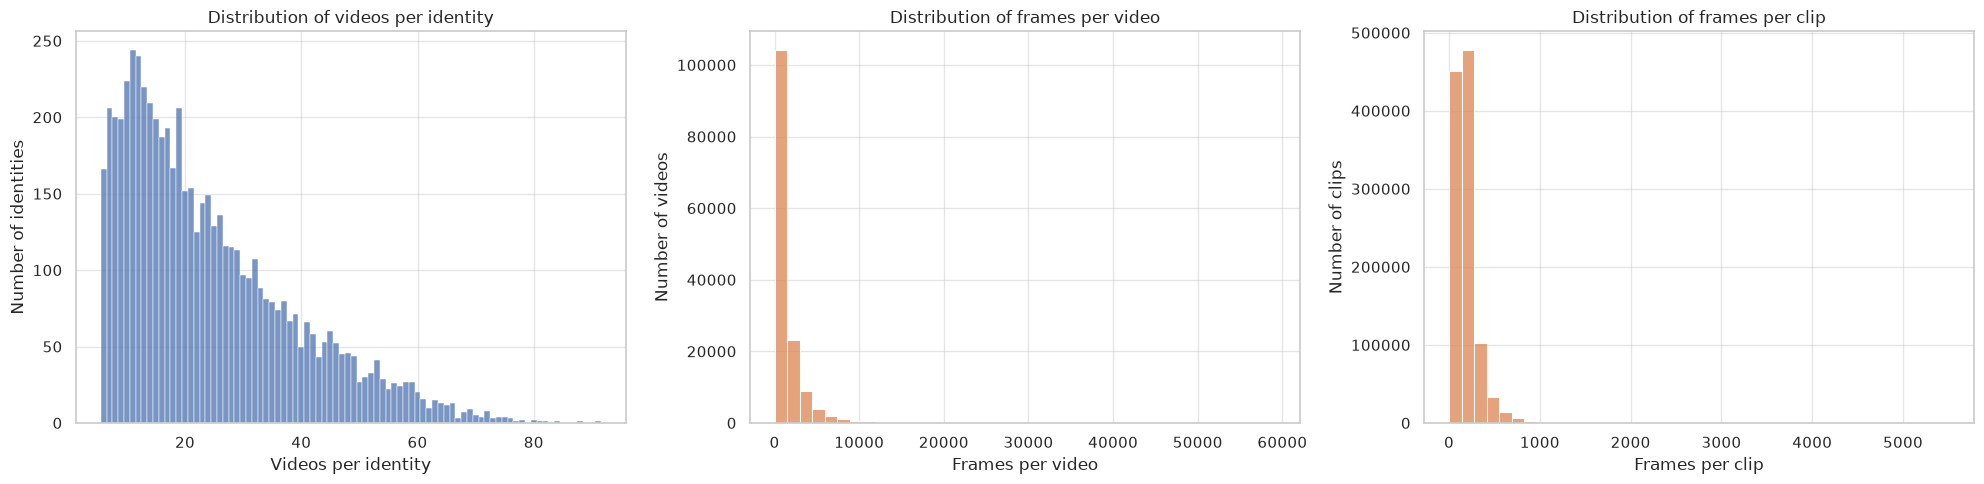

In [18]:
from matplotlib import pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Use only the clips that could be read.
clips_stats = clips[clips["ok"]]

videos_per_identity = clips_stats.groupby(["identity"])["video"].nunique()
print("\nVideos per identity")
print(videos_per_identity.describe().to_string())

frames_per_video = clips_stats.groupby(["identity", "video"])["frames"].sum()
print("\nFrames per video")
print(frames_per_video.describe().to_string())

frames_per_clip = clips_stats.groupby(["identity", "video", "clip"])["frames"].sum()
print("\nFrames per clip")
print(frames_per_clip.describe().to_string())

fig, (ax_1, ax_2, ax_3) = plt.subplots(1, 3, figsize=(20, 5))

# Distribution of videos per identity.
sns.histplot(videos_per_identity, discrete=True, color="#4C72B0", ax=ax_1)
ax_1.set_title("Distribution of videos per identity")
ax_1.set_xlabel("Videos per identity")
ax_1.set_ylabel("Number of identities")

# Distribution of frames per video.
sns.histplot(frames_per_video, bins=40, color="#DD8452", ax=ax_2)
ax_2.set_title("Distribution of frames per video")
ax_2.set_xlabel("Frames per video")
ax_2.set_ylabel("Number of videos")

# Distribution of frames per clip.
sns.histplot(frames_per_clip, bins=40, color="#DD8452", ax=ax_3)
ax_3.set_title("Distribution of frames per clip")
ax_3.set_xlabel("Frames per clip")
ax_3.set_ylabel("Number of clips")

fig.tight_layout()
plt.show()

In [19]:
FRAMES = ROOT / "data/voxceleb2"
STRUCTURE = ROOT / "data/voxceleb2.parquet"

SEED = 0
CLIPS_PER_VIDEO = 4
SECONDS = 20  # taken from the start of each clip
EXTRACT_CHUNK = 500  # clips per task


def extract_clips(task: tuple[Path, list[str]]) -> int:
    """
    Write one frame per second of each clip to ``FRAMES/identity/video/clip.second.jpg``.

    :param task: An archive and the member names to read out of it
    :return: How many frames were written
    """
    archive, members = task
    if archive not in HANDLES:
        HANDLES[archive] = zipfile.ZipFile(archive)
    handle = HANDLES[archive]

    written = 0
    with tempfile.TemporaryDirectory() as workspace:
        clip_file = Path(workspace) / "clip.mp4"
        for member in members:
            # dev/mp4/id00027/4H8NO-Ka_cs/00003.mp4
            _, _, identity, video, name = member.split("/")
            clip = name.removesuffix(".mp4")
            destination = FRAMES / identity / video

            # Already extracted, so an interrupted run continues instead of starting over.
            if (destination / f"{clip}.0000.jpg").exists():
                continue
            destination.mkdir(parents=True, exist_ok=True)

            clip_file.write_bytes(handle.read(member))
            capture = cv2.VideoCapture(str(clip_file))
            step = max(1, round(capture.get(cv2.CAP_PROP_FPS)))

            for index in range(step * SECONDS):
                # grab() advances the clip without decoding into an array; only the frames that
                # are kept are retrieved.
                if not capture.grab():
                    break
                if index % step:
                    continue
                ok, image = capture.retrieve()
                if ok:
                    cv2.imwrite(str(destination / f"{clip}.{index // step:04d}.jpg"), image)
                    written += 1
            capture.release()
    return written


if STRUCTURE.exists():
    structure = pd.read_parquet(STRUCTURE)
else:
    # Up to CLIPS_PER_VIDEO clips of every video, drawn at random but reproducibly.
    selection = (
        clips[clips["ok"]]
        .sample(frac=1, random_state=SEED)
        .groupby(["identity", "video"], sort=False)
        .head(CLIPS_PER_VIDEO)
    )
    wanted = {f"dev/mp4/{row.identity}/{row.video}/{row.clip}.mp4" for row in selection.itertuples()}

    tasks = []
    for archive in ARCHIVES:
        with zipfile.ZipFile(archive) as handle:
            members = [name for name in handle.namelist() if name in wanted]
        tasks += [(archive, members[start : start + EXTRACT_CHUNK]) for start in range(0, len(members), EXTRACT_CHUNK)]

    context = multiprocessing.get_context("fork")
    with ProcessPoolExecutor(max_workers=WORKERS, mp_context=context) as pool:
        written = sum(tqdm(pool.map(extract_clips, tasks), total=len(tasks), desc=f"{EXTRACT_CHUNK}-clip chunks"))
    print(f"wrote {written:,} frames")

    # Read back from disk, so that a resumed run and a clean run describe the same corpus.
    structure = pd.DataFrame(
        (
            (
                path.parts[-3],
                path.parts[-2],
                path.name.split(".")[0],
                int(path.name.split(".")[1]),
                path.name,
                path.suffix,
                str(path.relative_to(ROOT / "data")),
            )
            for path in FRAMES.rglob("*.jpg")
        ),
        columns=["identity", "video", "clip", "second", "frame", "frame_suffix", "path"],
    )
    structure = structure.sort_values(["identity", "video", "clip", "second"]).reset_index(drop=True)
    structure.to_parquet(STRUCTURE, index=False)

frames_per_video = structure.groupby(["identity", "video"]).size()
print(f"{len(structure):,} frames, {len(frames_per_video):,} videos, {structure['identity'].nunique():,} identities")
print(
    f"frames per video: median {frames_per_video.median():.0f}, "
    f"mean {frames_per_video.mean():.1f}, max {frames_per_video.max()}"
)
structure.head()


500-clip chunks:   0%|          | 0/889 [00:00<?, ?it/s]

wrote 3,400,602 frames
3,400,602 frames, 145,543 videos, 5,994 identities
frames per video: median 23, mean 23.4, max 80


,identity,video,clip,second,frame,frame_suffix,path
0,id00012,21Uxsk56VDQ,00006,0,00006.0000.jpg,.jpg,voxceleb2/id00012/21Uxsk56VDQ/00006.0000.jpg
1,id00012,21Uxsk56VDQ,00006,1,00006.0001.jpg,.jpg,voxceleb2/id00012/21Uxsk56VDQ/00006.0001.jpg
2,id00012,21Uxsk56VDQ,00006,2,00006.0002.jpg,.jpg,voxceleb2/id00012/21Uxsk56VDQ/00006.0002.jpg
3,id00012,21Uxsk56VDQ,00006,3,00006.0003.jpg,.jpg,voxceleb2/id00012/21Uxsk56VDQ/00006.0003.jpg
4,id00012,21Uxsk56VDQ,00006,4,00006.0004.jpg,.jpg,voxceleb2/id00012/21Uxsk56VDQ/00006.0004.jpg



Videos per identity
count    5994.000000
mean       24.281448
std        14.749820
min         6.000000
25%        13.000000
50%        20.000000
75%        33.000000
max        91.000000

Frames per video
count    145543.000000
mean         23.364930
std          13.160941
min           2.000000
25%          12.000000
50%          23.000000
75%          31.000000
max          80.000000

Frames per clip
count    442843.000000
mean          7.679024
std           3.692685
min           1.000000
25%           5.000000
50%           6.000000
75%           9.000000
max          20.000000


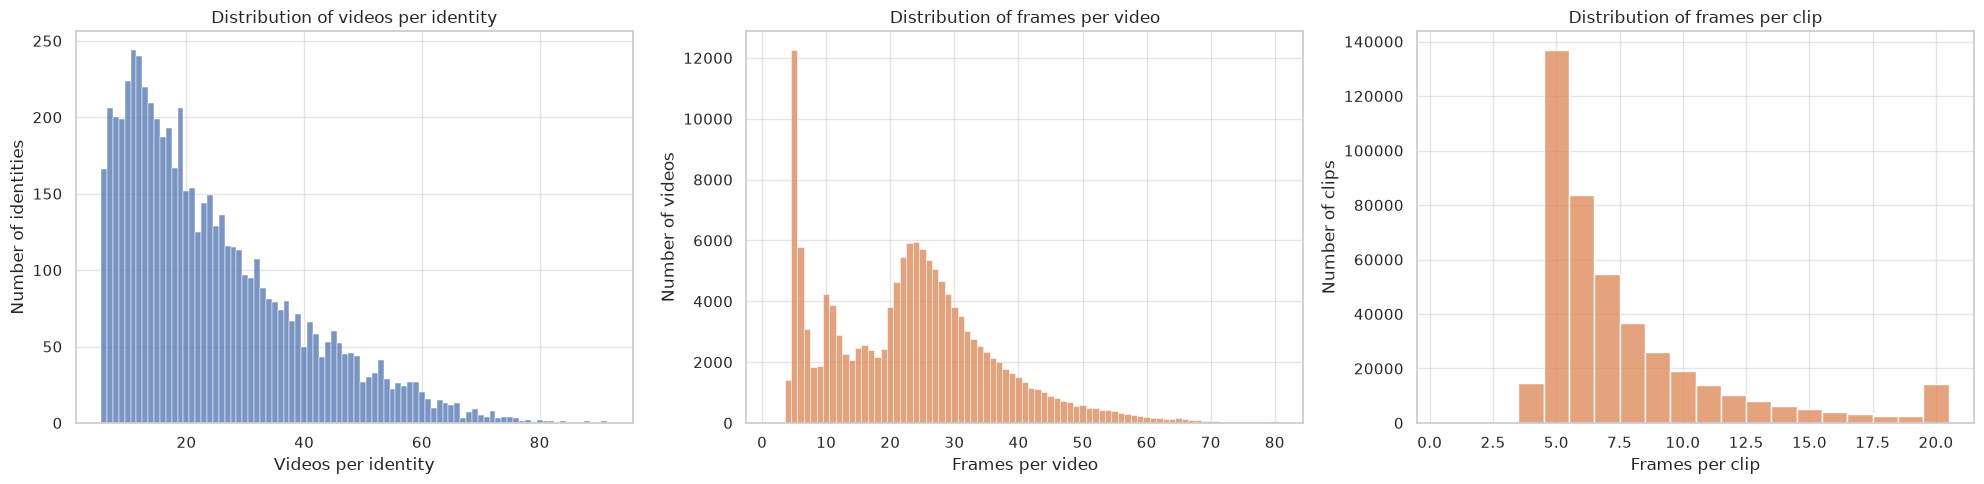

In [20]:
videos_per_identity = structure.groupby(["identity"])["video"].nunique()
print("\nVideos per identity")
print(videos_per_identity.describe().to_string())

frames_per_video = structure.groupby(["identity", "video"]).size()
print("\nFrames per video")
print(frames_per_video.describe().to_string())

frames_per_clip = structure.groupby(["identity", "video", "clip"]).size()
print("\nFrames per clip")
print(frames_per_clip.describe().to_string())

fig, (ax_1, ax_2, ax_3) = plt.subplots(1, 3, figsize=(20, 5))

# Distribution of videos per identity.
sns.histplot(videos_per_identity, discrete=True, color="#4C72B0", ax=ax_1)
ax_1.set_title("Distribution of videos per identity")
ax_1.set_xlabel("Videos per identity")
ax_1.set_ylabel("Number of identities")

# Distribution of frames per video.
sns.histplot(frames_per_video, discrete=True, color="#DD8452", ax=ax_2)
ax_2.set_title("Distribution of frames per video")
ax_2.set_xlabel("Frames per video")
ax_2.set_ylabel("Number of videos")

# Distribution of frames per clip.
sns.histplot(frames_per_clip, discrete=True, color="#DD8452", ax=ax_3)
ax_3.set_title("Distribution of frames per clip")
ax_3.set_xlabel("Frames per clip")
ax_3.set_ylabel("Number of clips")

fig.tight_layout()
plt.show()
